# AI4CARE thesis results analysis

This notebook reads one experiment at a time: its run manifest, evaluation rows/checkpoints, traces, and any judge scores matched by run ID. It does not change the experiment data.

Run cells from top to bottom after new data is written. By default, it selects the newest thesis or full run and excludes pilot runs. Set RUN_DIR_OVERRIDE in the setup cell to select a particular experiment. Archived scores are shown separately when their run IDs do not match.

The notebook is ready to run before judging begins. If the selected experiment has no judge results yet, RQ3 is reported as NOT YET ASSESSED / INSUFFICIENT DATA. That means judging is pending, not that the judge hypothesis has failed.


## Research questions

**RQ1.** Do different decoder-only models yield measurably different schema completeness scores when conducting interviews over identical benchmark cases?

**RQ2.** How does elicitation efficiency vary across models in terms of turn-level novel-fact gain, redundancy rate, and total turns to completion?

**RQ3.** Does a blinded panel of independent judge models produce consistent inter-rater agreement, and can it reliably separate candidate model performance?

RQ1 and RQ2 use interview traces. RQ3 depends on the separate judging phase, which has not started for the current data.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Leave None to select the newest thesis/full run (pilot is excluded). Otherwise use a project-relative
# or absolute experiment folder. Judge override accepts a long-score CSV path.
RUN_DIR_OVERRIDE = None
JUDGE_RESULTS_OVERRIDE = None
BOOTSTRAP_REPLICATES = 2000
BOOTSTRAP_SEED = 42
RHO_THRESHOLD = 0.70

def find_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "evaluate.py").exists() and (p / "data" / "benchmark").exists():
            return p
    raise FileNotFoundError("Start Jupyter from the AI4CARE project folder or a subfolder.")

ROOT = find_root()
sys.path.insert(0, str(ROOT))
from evaluation_metrics import compute_all_metrics

def read_json(p):
    with p.open(encoding="utf-8") as f:
        return json.load(f)

def read_jsonl(p):
    rows, bad = [], 0
    if p.exists():
        with p.open(encoding="utf-8") as f:
            for line in f:
                if not line.strip():
                    continue
                try:
                    rows.append(json.loads(line))
                except json.JSONDecodeError:
                    bad += 1
    return rows, bad

def choose_run():
    if RUN_DIR_OVERRIDE:
        p = Path(RUN_DIR_OVERRIDE)
        p = p if p.is_absolute() else ROOT / p
        if not (p / "run_manifest.json").exists():
            raise FileNotFoundError(p / "run_manifest.json")
        return p
    candidates = []
    base = ROOT / "results" / "experiments"
    for profile in ("thesis", "full"):
        folder = base / profile
        if folder.exists():
            for manifest in folder.glob("*/run_manifest.json"):
                try:
                    record = read_json(manifest)
                    if record.get("profile") == profile:
                        candidates.append((record.get("created_at_utc", ""), manifest.parent))
                except (OSError, json.JSONDecodeError):
                    continue
    if not candidates:
        raise FileNotFoundError(f"No thesis/full run manifests under {base}")
    return max(candidates, key=lambda item: item[0])[1]

RUN_DIR = choose_run()
MANIFEST = read_json(RUN_DIR / "run_manifest.json")
CONFIG = MANIFEST.get("config", {})
print("Experiment:", RUN_DIR.name, "| profile:", MANIFEST.get("profile", "unknown"))
print("Created:", MANIFEST.get("created_at_utc", "unknown"))
print("Analysis refreshed:", datetime.now(timezone.utc).isoformat(timespec="seconds"))
selection = MANIFEST.get("model_selection", {})
print("Interviewer selection:", selection.get("method", "not recorded"))
for model in selection.get("selected_models", []):
    print("  -", model.get("model_id"), f"({model.get('params_b', '?')}B; estimated {model.get('estimated_memory_gb', '?')} GB)")
print("Judge stage:", (MANIFEST.get("stage_status") or {}).get("judging", "pending"))

Experiment: thesis_none_8models_1i_12c_4t_20261110T124956Z | profile: thesis
Created: 2026-11-10T12:49:56.749661+00:00
Analysis refreshed: 2026-11-10T14:06:19+00:00
Interviewer selection: estimator hardware fit at Q4_K_M / 2048 context
  - phi-3.5-mini-instruct (3.82B; estimated 3.67 GB)
  - llama-3.2-3b-instruct (3.21B; estimated 2.58 GB)
  - qwen2.5-3b-instruct (3.09B; estimated 2.31 GB)
  - deepseek-r1-distill-qwen-1.5b (1.78B; estimated 1.35 GB)
  - qwen3-1.7b (1.78B; estimated 1.55 GB)
  - phi-4-mini-instruct (3.8B; estimated 3.04 GB)
  - qwen2.5-1.5b-instruct (1.54B; estimated 1.17 GB)
  - llama-3.2-1b-instruct (1.23B; estimated 0.96 GB)
Judge stage: pending


In [2]:
progress=[]
pdirectory=RUN_DIR/"trace_shards"
if pdirectory.exists():
    for p in sorted(pdirectory.glob("*.progress.json")):
        try:
            x=read_json(p)
            progress.append({
                "Model":x.get("model_id",p.stem),"Recorded status":x.get("status","unknown"),
                "Completed":x.get("completed",0),"Planned":x.get("total",0),
                "Active episode records":len(x.get("active_episodes") or {}),
                "Checkpoint UTC":datetime.fromtimestamp(x["updated_at"],timezone.utc).isoformat(timespec="seconds") if x.get("updated_at") else "unknown"
            })
        except (OSError,json.JSONDecodeError): pass
models_planned=CONFIG.get("model_ids") or []
expected=None
if models_planned and CONFIG.get("iterations") is not None and CONFIG.get("cases_per_iteration") is not None:
    expected=len(models_planned)*int(CONFIG["iterations"])*int(CONFIG["cases_per_iteration"])
print("Recorded stages:",MANIFEST.get("stage_status",{}))
print("Models:",models_planned or "not in manifest")
print("Benchmark variants:",MANIFEST.get("benchmark_cases_available","unknown"))
print("Independent source documents:",MANIFEST.get("independent_source_cases","unknown"))
print("Planned model-by-variant episodes:",expected if expected is not None else "unknown")
display(pd.DataFrame(progress) if progress else pd.DataFrame({"Progress":["No per-model snapshots yet"]}))

Recorded stages: {'generation': 'pending', 'judging': 'pending', 'analysis': 'pending'}
Models: ['phi-3.5-mini-instruct', 'llama-3.2-3b-instruct', 'qwen2.5-3b-instruct', 'deepseek-r1-distill-qwen-1.5b', 'qwen3-1.7b', 'phi-4-mini-instruct', 'qwen2.5-1.5b-instruct', 'llama-3.2-1b-instruct']
Benchmark variants: 57
Independent source documents: 3
Planned model-by-variant episodes: 96


,Model,Recorded status,Completed,Planned,Active episode records,Checkpoint UTC
0,deepseek-r1-distill-qwen-1.5b,running,6,12,1,2026-11-10T14:00:31+00:00
1,llama-3.2-3b-instruct,running,1,12,1,2026-11-10T14:04:18+00:00
2,phi-3.5-mini-instruct,running,1,12,1,2026-11-10T13:57:54+00:00
3,qwen2.5-3b-instruct,running,7,12,1,2026-11-10T14:03:50+00:00


## Metrics, expected values, and decision rules

Interpret every measure against the research question it addresses. The notebook does not create a pass mark after seeing the results. The two numeric criteria specified in the analysis plan are: (1) a paired, source-cluster bootstrap interval that excludes zero for a model difference, and (2) at least two judge pairs with Spearman rho > 0.70 for RQ3 reliability.

| Research question / measure | What the values mean | What would support the question | What would count against it or remain unresolved |
|---|---|---|---|
| RQ1: schema_completeness (0-1) | Higher values mean more of the nine knowledge fields reached stronger evidence states. 1 is the maximum. The 0.75 setting is the interview stopping target, not a thesis success cutoff. | A paired difference whose 95% source-cluster bootstrap interval excludes 0 supports a measurable model difference on these benchmark assignments. The sign identifies the higher-scoring model. | If intervals include 0, this run did not resolve a difference; it does not prove models are equal. High completeness alone does not prove correctness. |
| RQ1: reference precision, recall, and reference_fact_f1 (0-1) | Precision is the share of extracted claim units matched; recall is the share of exposed source sentences matched; F1 balances the two. The reference denominator is limited to sentences the synthetic respondent disclosed in that episode. | Higher, nonzero scores support technical feasibility of extracting source-grounded information from the disclosed replies. Compare models on the same cases and alongside exposure. | No absolute F1 pass threshold is preregistered. A low result weighs against this implementation's extraction fidelity. Matching is lexical, so it can miss valid paraphrases and cannot certify semantic truth. Missing exposure metadata produces null F1 rather than treating the entire source as exposed. |
| Exposure: reference_fact_exposure_rate | Exposed source sentences divided by all source sentences in the case. It describes what the respondent made available, not what the interviewer extracted. | Similar exposure across models makes F1 comparisons easier to interpret. | Unequal exposure may explain some F1 differences; always inspect it with F1 and the respondent evidence indices. |
| Evidence support: evidence_text_support_rate | Share of extracted updates whose evidence text passes the fixed 0.80 lexical-support check against the participant reply. | Higher values support traceability between the reply and extracted fields. | This is an automatic lexical check, not entailment or human fact checking. |
| RQ2: novelty, gap targeting, redundancy, and turns | Favorable directions are: more novel_fields_per_response, higher gap_targeting_rate, lower question_redundancy_rate, and fewer turn_count. | A consistent improvement in those directions, without lower F1 or schema completeness, supports greater elicitation efficiency. | Fewer turns alone can mean early stopping without sufficient information. Do not call a model efficient if it produces less grounded knowledge. No single metric has an absolute pass threshold. |
| RQ3: judge quality score (0-4), panel median, and MAD | Higher rubric scores indicate better judged follow-up quality; lower median absolute deviation (MAD) indicates closer judge scores. A MAD of 0 means exact agreement for that trace. | Scores of 3-4 mean good/excellent under the rubric. The analysis plan's reliability criterion is at least two judge pairs with rho > 0.70. Four judges yield six possible pairs. | A score of 3 is not a separate thesis pass threshold. A correlation cannot be estimated with fewer than three shared traces or with no rating variation. With no matched judge rows, RQ3 is pending/insufficient, not disproved. Judge agreement is not proof of truth. |

### Limits on inference

The 12-case thesis profile gives every interviewer the same four variants from each of the three independent source documents. The 57-variant exhaustive profile covers more prompts but still only three independent documents. Variants within a document are repeated tasks, not new independent sources; source-cluster intervals are therefore coarse. All participant replies are generated by the deterministic synthetic respondent. Positive results show feasibility on this benchmark, not proof of extraction from real employees or general workforce performance.


In [3]:
# Load benchmark facts and checkpoint/final traces; derive metrics with the
# same production function used by evaluate.py when only traces are present.
facts, fact_bad = read_jsonl(ROOT / "data" / "benchmark" / "benchmark_facts.jsonl")
facts_by_case = {}
for fact in facts:
    facts_by_case.setdefault(str(fact.get("case_id", "")), []).append(fact)

trace_paths = []
canonical = RUN_DIR / "evaluation_traces.jsonl"
if canonical.exists():
    trace_paths.append(canonical)
if (RUN_DIR / "trace_shards").exists():
    trace_paths += sorted((RUN_DIR / "trace_shards").glob("*.jsonl"))
trace_by_id, trace_bad, file_counts = {}, 0, {}
for p in trace_paths:
    recs, bad = read_jsonl(p)
    trace_bad += bad
    file_counts[p.name] = len(recs)
    for rec in recs:
        rid = str(rec.get("run_id", "")).strip()
        if rid:
            trace_by_id[rid] = rec

def make_row(rec):
    trace = rec.get("trace") or {}
    turns = trace.get("turns") or []
    case_id = str(rec.get("case_id", ""))
    row = {k: rec.get(k) for k in [
        "run_id", "experiment_id", "run_profile", "iteration_id", "model_id", "case_id",
        "case_group_id", "question_variant_id", "variant_key", "case_category", "ablation",
        "config_fingerprint", "benchmark_hash", "evaluation_schema_version", "status",
        "failure_reason", "effective_extraction_temperature", "effective_question_temperature",
        "effective_seed", "total_runtime_ms"]}
    row["status"] = row.get("status") or ("success" if trace else "unknown")
    row["turn_count"] = trace.get("turn_count", len(turns))
    row["llm_calls"] = sum((t.get("extraction_llm_calls", 0) if t.get("role") == "participant" else 0) + (1 if t.get("generation_latency_ms") else 0) for t in turns)
    row["prompt_tokens"] = sum((t.get("extraction_prompt_tokens", 0) if t.get("role") == "participant" else 0) + t.get("generation_prompt_tokens", 0) for t in turns)
    row["completion_tokens"] = sum((t.get("extraction_completion_tokens", 0) if t.get("role") == "participant" else 0) + t.get("generation_completion_tokens", 0) for t in turns)
    if row["status"] == "success" and trace:
        row.update(compute_all_metrics(trace, facts_by_case.get(case_id) or None, case_id, ablation=str(rec.get("ablation") or "none")))
    return row

combined = {rid: make_row(rec) for rid, rec in trace_by_id.items()}
csv_path = RUN_DIR / "evaluation_results.csv"
csv_count = 0
if csv_path.exists():
    try:
        eval_df = pd.read_csv(csv_path, dtype=str, keep_default_na=False, low_memory=False)
        csv_count = len(eval_df)
        for rec in eval_df.to_dict("records"):
            rid = str(rec.get("run_id", "")).strip()
            if rid:
                row = dict(combined.get(rid, {}))
                row.update({k: v for k, v in rec.items() if v is not None and str(v).strip() != ""})
                combined[rid] = row
    except (OSError, UnicodeDecodeError, pd.errors.ParserError) as exc:
        print("Evaluation CSV read issue:", exc)

results = pd.DataFrame(combined.values())
if results.empty:
    results = pd.DataFrame(columns=["run_id", "model_id", "case_id", "case_group_id", "status"])
numeric = ["turn_count", "total_runtime_ms", "llm_calls", "prompt_tokens", "completion_tokens",
"reference_fact_precision", "reference_fact_recall", "reference_fact_f1", "schema_completeness",
"novel_fields_total", "novel_fields_per_response", "question_redundancy_rate", "gap_targeting_rate",
"conflicting_field_rate", "evidence_presence_rate", "llm_extraction_count", "fallback_extraction_count",
"empty_extraction_count", "extraction_llm_calls", "follow_up_question_quality", "judge_disagreement_mad"]
for c in numeric:
    if c in results:
        results[c] = pd.to_numeric(results[c], errors="coerce")
for c in ["model_id", "case_id", "case_group_id", "question_variant_id", "variant_key", "ablation", "status"]:
    if c not in results:
        results[c] = ""
    results[c] = results[c].fillna("").astype(str)
results["_group"] = results["case_group_id"].where(results["case_group_id"].str.strip() != "", results["case_id"])
results["_variant"] = results["question_variant_id"].where(results["question_variant_id"].str.strip() != "", results["variant_key"].where(results["variant_key"].str.strip() != "", results["case_id"]))
results["_success"] = results["status"].str.lower().isin(["success", "ok"])
successful = results[results["_success"]].copy()
source_labels = {}
if len(successful) and "case_category" in successful:
    for group, part in successful.groupby("_group", dropna=False):
        categories = part["case_category"].dropna().astype(str).loc[lambda x: x.str.strip() != ""]
        if len(categories): source_labels[str(group)] = categories.mode().iloc[0].title()
def source_label(group):
    return source_labels.get(str(group), str(group)[:12])

planned_per_model = None
if CONFIG.get("iterations") is not None and CONFIG.get("cases_per_iteration") is not None:
    planned_per_model = int(CONFIG["iterations"]) * int(CONFIG["cases_per_iteration"])
expected = planned_per_model * len(CONFIG.get("model_ids") or []) if planned_per_model is not None else None
coverage_rows = []
for model in sorted(set(CONFIG.get("model_ids") or []) | set(results["model_id"].unique())):
    observed = int(results.loc[results["model_id"] == model, "run_id"].nunique())
    succeeded = int(successful.loc[successful["model_id"] == model, "run_id"].nunique())
    coverage_rows.append({"Model": model, "Episodes recorded": observed, "Successful": succeeded,
                          "Planned": planned_per_model, "Not yet recorded": max(0, planned_per_model-observed) if planned_per_model is not None else None})
coverage = pd.DataFrame(coverage_rows)
model_coverage_complete = (planned_per_model is not None and all(int(results.loc[results["model_id"] == model, "run_id"].nunique()) >= planned_per_model for model in (CONFIG.get("model_ids") or [])))
episode_coverage_complete = bool(model_coverage_complete)

print("Trace files:", file_counts or "none")
print("Reference facts:", len(facts), "across", len(facts_by_case), "cases")
print("Malformed/incomplete lines skipped:", trace_bad + fact_bad)
print("Final evaluation CSV rows:", csv_count)
print(f"Unique episodes: {len(results):,}; successful: {len(successful):,}; planned: {expected if expected is not None else 'unknown'}")
print("Manifest generation stage:", MANIFEST.get("stage_status", {}).get("generation", "not recorded"))
display(coverage)
display(pd.DataFrame([
    ["Successful episodes", len(successful)],
    ["Independent source groups", successful["_group"].replace("", np.nan).nunique() if len(successful) else 0],
    ["Variants observed", successful["_variant"].replace("", np.nan).nunique() if len(successful) else 0],
    ["Episode coverage complete", episode_coverage_complete],
], columns=["Coverage check", "Value"]))
if len(successful) and "schema_completeness" in successful:
    stop_threshold=float(CONFIG.get("completion_threshold",0.75))
    turn_cap=int(CONFIG.get("max_turns",15))
    termination=[]
    for model,part in successful.groupby("model_id"):
        completeness=pd.to_numeric(part["schema_completeness"],errors="coerce")
        turns=pd.to_numeric(part.get("turn_count",pd.Series(np.nan,index=part.index)),errors="coerce")
        termination.append({"Model":model,"Mean completeness":completeness.mean(),
            f"Episodes at/above stop threshold ({stop_threshold:.2f})":int((completeness>=stop_threshold).sum()),
            "Episodes at turn cap":int((turns>=turn_cap).sum()),"Successful episodes":len(part)})
    print(f"Episode termination diagnostic: {stop_threshold:.2f} is the configured stop target, not a thesis pass score; turn cap={turn_cap}.")
    display(pd.DataFrame(termination).round(3))
if not episode_coverage_complete and expected is not None:
    print("INSUFFICIENT FOR FINAL FULL-RUN CONCLUSIONS: at least one planned model-by-variant episode is absent.")

Trace files: {'deepseek-r1-distill-qwen-1.5b.jsonl': 6, 'llama-3.2-3b-instruct.jsonl': 1, 'phi-3.5-mini-instruct.jsonl': 1, 'qwen2.5-3b-instruct.jsonl': 7}
Reference facts: 4649 across 3 cases
Malformed/incomplete lines skipped: 0
Final evaluation CSV rows: 0
Unique episodes: 15; successful: 15; planned: 96
Manifest generation stage: pending


,Model,Episodes recorded,Successful,Planned,Not yet recorded
0,deepseek-r1-distill-qwen-1.5b,6,6,12,6
1,llama-3.2-1b-instruct,0,0,12,12
2,llama-3.2-3b-instruct,1,1,12,11
3,phi-3.5-mini-instruct,1,1,12,11
4,phi-4-mini-instruct,0,0,12,12
5,qwen2.5-1.5b-instruct,0,0,12,12
6,qwen2.5-3b-instruct,7,7,12,5
7,qwen3-1.7b,0,0,12,12


,Coverage check,Value
0,Successful episodes,15
1,Independent source groups,3
2,Variants observed,7
3,Episode coverage complete,False


Episode termination diagnostic: 0.75 is the configured stop target, not a thesis pass score; turn cap=4.


,Model,Mean completeness,Episodes at/above stop threshold (0.75),Episodes at turn cap,Successful episodes
0,deepseek-r1-distill-qwen-1.5b,0.160,0,6,6
1,llama-3.2-3b-instruct,0.222,0,1,1
2,phi-3.5-mini-instruct,0.111,0,1,1
3,qwen2.5-3b-instruct,0.138,0,7,7


INSUFFICIENT FOR FINAL FULL-RUN CONCLUSIONS: at least one planned model-by-variant episode is absent.


## RQ1 — extraction outcomes and model differences

Use the paired model comparisons to answer whether models differ on identical case/question assignments. The forest plot displays each model A minus model B estimate with its 95% bootstrap interval; intervals wholly above zero favor A, wholly below zero favor B, and intervals crossing zero leave that comparison unresolved. Box/violin distributions and source-group summaries show spread and whether one document drives the pattern.

Read schema completeness as progress through the knowledge-state rubric, not factual accuracy. Read reference precision/recall/F1 as lexical agreement with the source sentences actually disclosed by the respondent. Inspect reference_fact_exposure_rate and evidence_text_support_rate beside F1. Null F1 means no usable exposed denominator or missing reference facts; do not turn null into zero.


In [4]:
def cluster_ci(frame,metric):
    part=frame[["_group",metric]].copy()
    part[metric]=pd.to_numeric(part[metric],errors="coerce")
    part=part.dropna(subset=[metric])
    groups={str(k):v[metric].to_numpy(float) for k,v in part.groupby("_group",dropna=False)}
    keys=list(groups)
    if len(keys)<2:return np.nan,np.nan,len(keys)
    rng=np.random.default_rng(BOOTSTRAP_SEED); samples=np.empty(BOOTSTRAP_REPLICATES)
    for i in range(len(samples)):
        chosen=rng.choice(keys,len(keys),replace=True)
        samples[i]=np.concatenate([groups[k] for k in chosen]).mean()
    lo,hi=np.quantile(samples,[.025,.975])
    return float(lo),float(hi),len(keys)

rq1_metrics=[("schema_completeness","Schema completeness"),("reference_fact_f1","Reference-fact F1"),
("reference_fact_precision","Reference-fact precision"),("reference_fact_recall","Reference-fact recall")]
summary=[]
if len(successful):
    for (ablation,model),part in successful.groupby(["ablation","model_id"],dropna=False):
        for metric,label in rq1_metrics:
            if metric not in part:continue
            vals=pd.to_numeric(part[metric],errors="coerce").dropna()
            lo,hi,ng=cluster_ci(part,metric)
            summary.append({"ablation":ablation,"model":model,"Metric":label,"episodes":len(vals),
            "source groups":ng,"mean":vals.mean() if len(vals) else np.nan,
            "median":vals.median() if len(vals) else np.nan,
            "SD":vals.std(ddof=1) if len(vals)>1 else np.nan,"95% CI low":lo,"95% CI high":hi})
rq1_summary=pd.DataFrame(summary)
display(rq1_summary.round(4) if len(rq1_summary) else pd.DataFrame({"RQ1":"Waiting for successful traces"}))

# Exact assignment paired differences (A minus B).
pairs=[]
if len(successful):
    temp=successful.copy()
    temp["_iteration"]=temp["iteration_id"].fillna("").astype(str) if "iteration_id" in temp else ""
    keys=["case_id","_variant","_iteration","ablation"]
    model_list=sorted(m for m in temp.model_id.unique() if m)
    for ablation in sorted(a for a in temp.ablation.unique() if a):
        data=temp[temp.ablation==ablation]
        for metric,label in rq1_metrics[:2]:
            if metric not in data:continue
            for i,a in enumerate(model_list):
                for b in model_list[i+1:]:
                    left=data[data.model_id==a][keys+["_group",metric]].rename(columns={metric:"value_a"})
                    right=data[data.model_id==b][keys+[metric]].rename(columns={metric:"value_b"})
                    m=left.merge(right,on=keys,how="inner",validate="one_to_one").dropna(subset=["value_a","value_b"])
                    if m.empty:continue
                    m["diff"]=pd.to_numeric(m.value_a)-pd.to_numeric(m.value_b)
                    groups={str(k):v["diff"].to_numpy(float) for k,v in m.groupby("_group",dropna=False)}
                    gkeys=list(groups); lo=hi=np.nan
                    if len(gkeys)>=2:
                        rng=np.random.default_rng(BOOTSTRAP_SEED); boot=np.empty(BOOTSTRAP_REPLICATES)
                        for j in range(len(boot)):boot[j]=np.concatenate([groups[k] for k in rng.choice(gkeys,len(gkeys),replace=True)]).mean()
                        lo,hi=np.quantile(boot,[.025,.975])
                    pairs.append({"ablation":ablation,"Metric":label,"Model A":a,"Model B":b,
                    "paired episodes":len(m),"source groups":len(gkeys),"mean A−B":m["diff"].mean(),
                    "95% CI low":lo,"95% CI high":hi})
pair_summary=pd.DataFrame(pairs)
display(pair_summary.round(4) if len(pair_summary) else pd.DataFrame({"Paired comparisons":"Need at least two models sharing assignments"}))

,ablation,model,Metric,episodes,source groups,mean,median,SD,95% CI low,95% CI high
0,none,deepseek-r1-distill-qwen-1.5b,Schema completeness,6,3,0.1605,0.1481,0.0302,0.1481,0.1728
1,none,deepseek-r1-distill-qwen-1.5b,Reference-fact F1,6,3,0.5242,0.5227,0.0756,0.5000,0.5727
2,none,deepseek-r1-distill-qwen-1.5b,Reference-fact precision,6,3,0.6167,0.6000,0.2229,0.6000,0.6333
3,none,deepseek-r1-distill-qwen-1.5b,Reference-fact recall,6,3,0.5103,0.5500,0.1116,0.4286,0.5500
4,none,llama-3.2-3b-instruct,Schema completeness,1,1,0.2222,0.2222,NaN,NaN,NaN
5,none,llama-3.2-3b-instruct,Reference-fact F1,1,1,0.5714,0.5714,NaN,NaN,NaN
6,none,llama-3.2-3b-instruct,Reference-fact precision,1,1,0.8000,0.8000,NaN,NaN,NaN
7,none,llama-3.2-3b-instruct,Reference-fact recall,1,1,0.4444,0.4444,NaN,NaN,NaN
8,none,phi-3.5-mini-instruct,Schema completeness,1,1,0.1111,0.1111,NaN,NaN,NaN
9,none,phi-3.5-mini-instruct,Reference-fact F1,1,1,0.1250,0.1250,NaN,NaN,NaN


,ablation,Metric,Model A,Model B,paired episodes,source groups,mean A−B,95% CI low,95% CI high
0,none,Schema completeness,deepseek-r1-distill-qwen-1.5b,llama-3.2-3b-instruct,1,1,-0.0741,NaN,NaN
1,none,Schema completeness,deepseek-r1-distill-qwen-1.5b,phi-3.5-mini-instruct,1,1,0.0370,NaN,NaN
2,none,Schema completeness,deepseek-r1-distill-qwen-1.5b,qwen2.5-3b-instruct,6,3,0.0494,0.0000,0.0617
3,none,Schema completeness,llama-3.2-3b-instruct,phi-3.5-mini-instruct,1,1,0.1111,NaN,NaN
4,none,Schema completeness,llama-3.2-3b-instruct,qwen2.5-3b-instruct,1,1,0.1111,NaN,NaN
5,none,Schema completeness,phi-3.5-mini-instruct,qwen2.5-3b-instruct,1,1,0.0000,NaN,NaN
6,none,Reference-fact F1,deepseek-r1-distill-qwen-1.5b,llama-3.2-3b-instruct,1,1,0.0286,NaN,NaN
7,none,Reference-fact F1,deepseek-r1-distill-qwen-1.5b,phi-3.5-mini-instruct,1,1,0.4750,NaN,NaN
8,none,Reference-fact F1,deepseek-r1-distill-qwen-1.5b,qwen2.5-3b-instruct,6,3,0.3345,0.2455,0.5000
9,none,Reference-fact F1,llama-3.2-3b-instruct,phi-3.5-mini-instruct,1,1,0.4464,NaN,NaN


RQ1 decision: PROVISIONAL / INSUFFICIENT — the planned full model-by-variant set is not present.


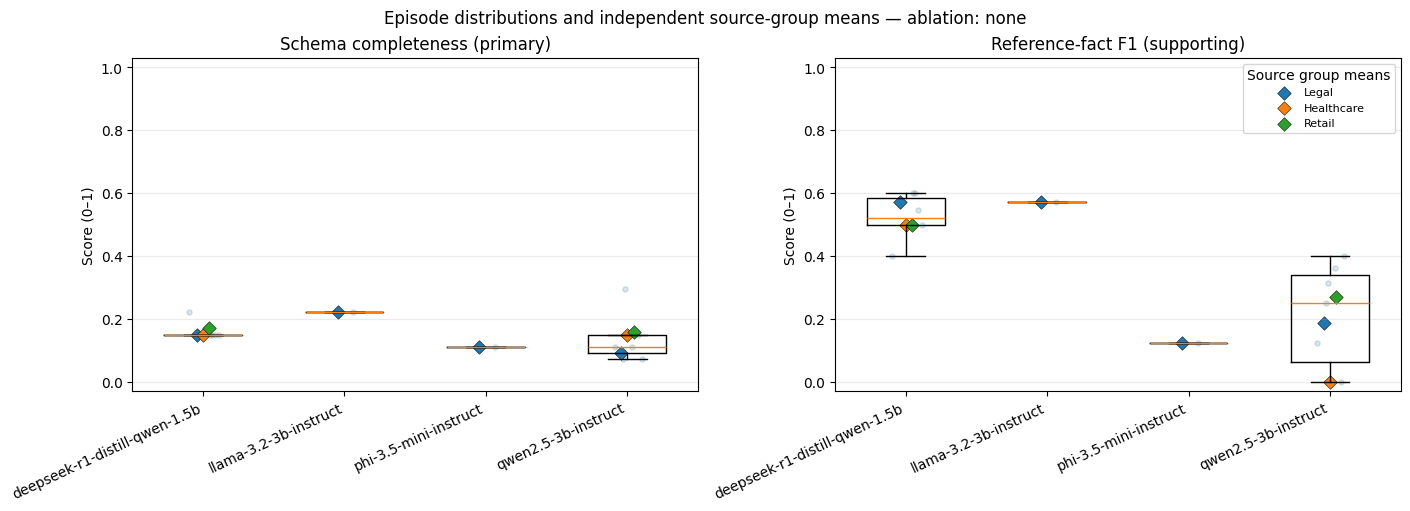

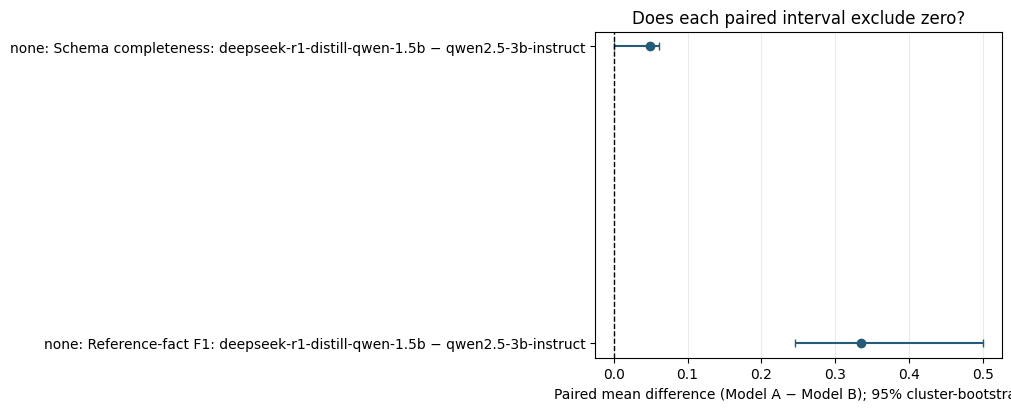

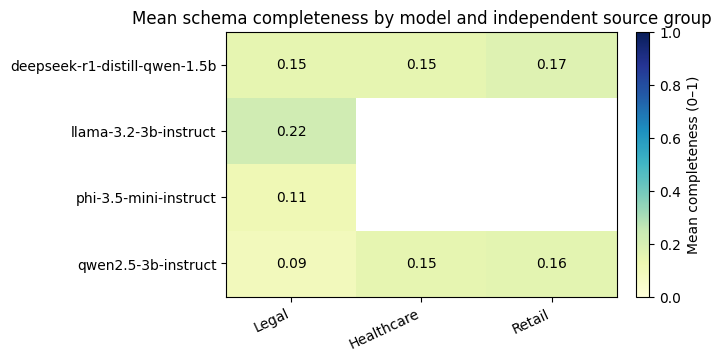

In [5]:
# Decision text plus plots chosen for categorical, paired, and clustered data.
schema_pairs = pair_summary[pair_summary["Metric"] == "Schema completeness"].copy() if len(pair_summary) else pd.DataFrame()
resolved_schema = schema_pairs[(schema_pairs["95% CI low"] > 0) | (schema_pairs["95% CI high"] < 0)] if len(schema_pairs) else pd.DataFrame()
if not episode_coverage_complete:
    print("RQ1 decision: PROVISIONAL / INSUFFICIENT — the planned full model-by-variant set is not present.")
elif len(resolved_schema):
    print(f"RQ1 decision: evidence of a measurable schema-completeness difference for {len(resolved_schema)} model pair(s) on this benchmark; inspect the direction in the paired-difference plot.")
else:
    print("RQ1 decision: no pairwise schema-completeness interval excludes zero. This is inconclusive about differences, not proof that models are equal.")

if len(successful):
    model_order = sorted(m for m in successful.model_id.unique() if m)
    plot_abl = "none" if "none" in set(successful.ablation) else sorted(successful.ablation.unique())[0]
    dat = successful[successful.ablation == plot_abl]
    # Box-and-jitter plots show skew, spread, and actual episode values. The
    # larger source-group markers expose the true independent-unit structure.
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
    for ax, (metric, title) in zip(axes, [
        ("schema_completeness", "Schema completeness (primary)"),
        ("reference_fact_f1", "Reference-fact F1 (supporting)"),
    ]):
        positions = np.arange(1, len(model_order) + 1)
        data = [pd.to_numeric(dat.loc[dat.model_id == m, metric], errors="coerce").dropna().to_numpy(float) for m in model_order]
        if not any(len(x) for x in data):
            ax.set_visible(False)
            continue
        nonempty = [(i+1, vals) for i, vals in enumerate(data) if len(vals)]
        ax.boxplot([v for _, v in nonempty], positions=[i for i, _ in nonempty], widths=.55, showfliers=False)
        rng = np.random.default_rng(BOOTSTRAP_SEED)
        for pos, vals in nonempty:
            ax.scatter(pos + rng.uniform(-.12, .12, len(vals)), vals, alpha=.20, s=14, color="#3B82A0")
        group_means = dat.groupby(["model_id", "_group"])[metric].mean().reset_index()
        group_names = sorted(group_means["_group"].unique())
        for gi, group in enumerate(group_names):
            one = group_means[group_means["_group"] == group].set_index("model_id")[metric].reindex(model_order)
            ax.scatter(positions + (gi-(len(group_names)-1)/2)*.045, one, marker="D", s=48, label=source_label(group), edgecolor="black", linewidth=.35)
        ax.set_xticks(positions, model_order, rotation=25, ha="right")
        ax.set_title(title)
        ax.set_ylabel("Score (0–1)")
        ax.set_ylim(-.03, 1.03)
        ax.grid(axis="y", alpha=.25)
    axes[1].legend(title="Source group means", fontsize=8)
    fig.suptitle(f"Episode distributions and independent source-group means — ablation: {plot_abl}")
    plt.show()

    # Forest plot directly compares each paired CI with the zero-difference line.
    forest = pair_summary[pair_summary["Metric"].isin(["Schema completeness", "Reference-fact F1"])].copy()
    forest = forest.dropna(subset=["95% CI low", "95% CI high"])
    if len(forest):
        forest["label"] = forest["ablation"] + ": " + forest["Metric"] + ": " + forest["Model A"] + " − " + forest["Model B"]
        fig, ax = plt.subplots(figsize=(10, max(4, .36*len(forest))), constrained_layout=True)
        y = np.arange(len(forest))
        x = forest["mean A−B"].to_numpy(float)
        low = x - forest["95% CI low"].to_numpy(float)
        high = forest["95% CI high"].to_numpy(float) - x
        ax.errorbar(x, y, xerr=np.vstack([low, high]), fmt="o", capsize=3, color="#245B78")
        ax.axvline(0, color="black", linestyle="--", linewidth=1)
        ax.set_yticks(y, forest["label"])
        ax.invert_yaxis()
        ax.set_xlabel("Paired mean difference (Model A − Model B); 95% cluster-bootstrap CI")
        ax.set_title("Does each paired interval exclude zero?")
        ax.grid(axis="x", alpha=.25)
        plt.show()
    else:
        print("Forest plot unavailable: no estimable paired intervals yet.")

    # Heatmap is suited to a rectangular model × independent-source-group summary.
    heat = dat.pivot_table(index="model_id", columns="_group", values="schema_completeness", aggfunc="mean").reindex(index=model_order)
    if heat.size:
        fig, ax = plt.subplots(figsize=(max(7, 2+1.4*heat.shape[1]), max(3.5, .65*heat.shape[0])), constrained_layout=True)
        image = ax.imshow(heat.to_numpy(float), vmin=0, vmax=1, aspect="auto", cmap="YlGnBu")
        ax.set_xticks(range(len(heat.columns)), [source_label(x) for x in heat.columns], rotation=25, ha="right")
        ax.set_yticks(range(len(heat.index)), heat.index)
        ax.set_title("Mean schema completeness by model and independent source group")
        for i in range(heat.shape[0]):
            for j in range(heat.shape[1]):
                if pd.notna(heat.iloc[i,j]): ax.text(j, i, f"{heat.iloc[i,j]:.2f}", ha="center", va="center", color="black")
        fig.colorbar(image, ax=ax, label="Mean completeness (0–1)")
        plt.show()

## RQ2 — elicitation efficiency

Expected directions are **more novel fields per response**, **higher gap-targeting**, **lower redundancy**, and **fewer turns**. Runtime/calls/tokens are lower-cost context. No numeric pass thresholds or formal inferential test are specified for RQ2, so this section can describe whether the pattern is favorable but cannot claim a statistically established efficiency effect.

The plot uses categorical distribution plots rather than connecting model names with lines: model IDs have no natural numeric order. Box-and-jitter plots reveal both spread and individual episodes; source-group means remain visible so the 57 variants are not mistaken for 57 independent cases. A runtime-versus-completeness scatterplot shows the quality/cost trade-off. Plot types follow the data structure: [Seaborn's categorical-plot guidance](https://seaborn.pydata.org/tutorial/categorical.html) describes boxplots for category-wise distributions, while [Matplotlib's plot types](https://matplotlib.org/stable/plot_types/index.html) distinguish distribution plots, pairwise plots, and gridded matrices.

,ablation,model,Metric,expected direction,episodes,source groups,mean,median,SD
0,none,deepseek-r1-distill-qwen-1.5b,Novel fields per response,higher,6,3,1.000,1.000,0.316
1,none,deepseek-r1-distill-qwen-1.5b,Redundancy rate,lower,6,3,0.278,0.333,0.251
2,none,deepseek-r1-distill-qwen-1.5b,Gap-targeting rate,higher,6,3,0.000,0.000,0.000
3,none,deepseek-r1-distill-qwen-1.5b,Turns per episode,lower only if quality is maintained,6,3,4.000,4.000,0.000
4,none,deepseek-r1-distill-qwen-1.5b,Runtime (minutes),lower only if quality is maintained,6,3,7.577,6.478,3.039
5,none,deepseek-r1-distill-qwen-1.5b,LLM calls,lower only if quality is maintained,6,3,9.667,9.500,0.816
6,none,deepseek-r1-distill-qwen-1.5b,Prompt tokens,context,6,3,3057.167,3077.500,137.677
7,none,deepseek-r1-distill-qwen-1.5b,Completion tokens,context,6,3,750.000,784.500,178.363
8,none,llama-3.2-3b-instruct,Novel fields per response,higher,1,1,1.250,1.250,NaN
9,none,llama-3.2-3b-instruct,Redundancy rate,lower,1,1,0.000,0.000,NaN


Descriptive RQ2 leaders only (no prespecified threshold or formal test):


,Measure,Observed descriptive leader,Observed mean,Expected direction
0,Novel fields per response,llama-3.2-3b-instruct,1.250,higher
1,Redundancy rate,llama-3.2-3b-instruct,0.000,lower
2,Gap-targeting rate,qwen2.5-3b-instruct,0.476,higher
3,Turns per episode,deepseek-r1-distill-qwen-1.5b,4.000,lower only if quality is maintained


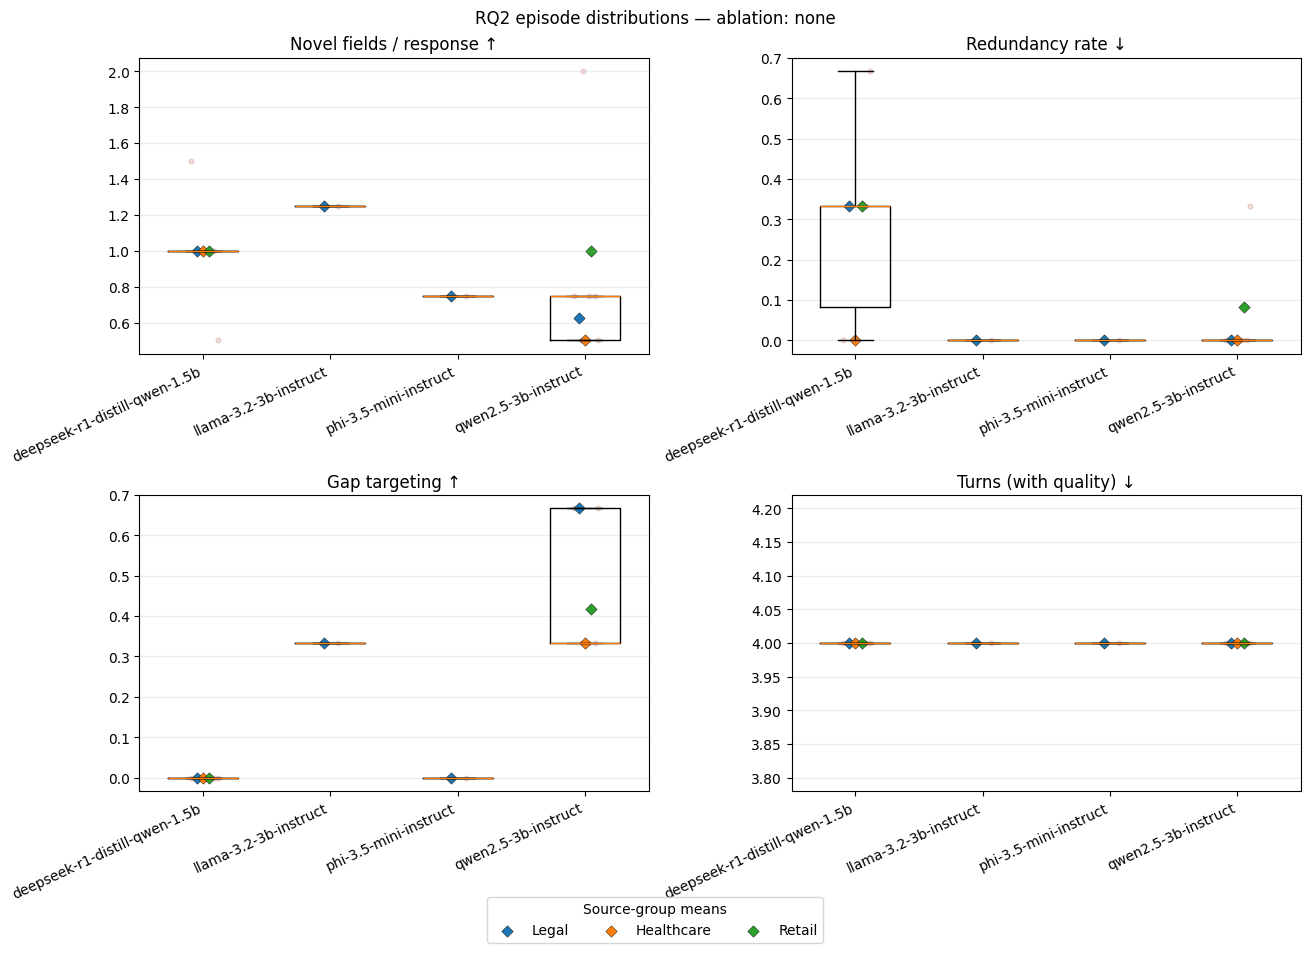

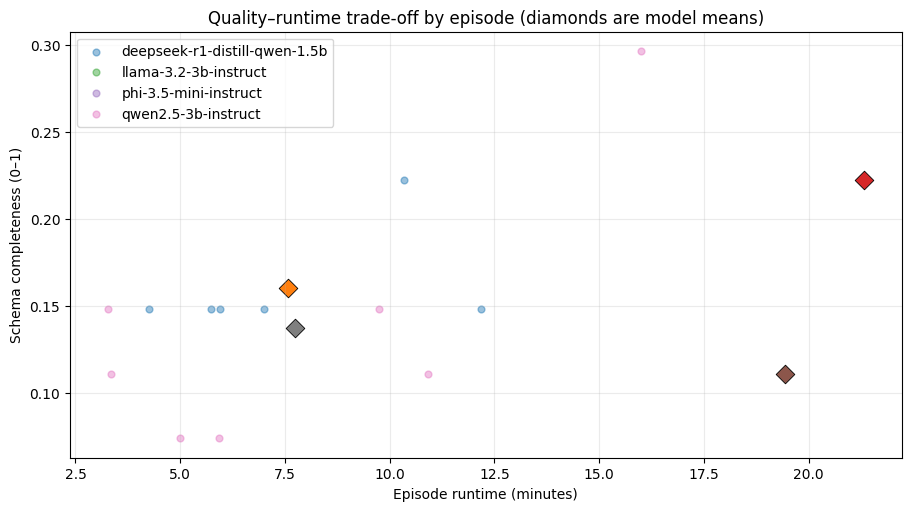

,ablation,model,Diagnostic,episodes,mean
0,none,deepseek-r1-distill-qwen-1.5b,Fallback extraction rate,6,0.3750
1,none,deepseek-r1-distill-qwen-1.5b,Fallback extractions,6,1.5000
2,none,deepseek-r1-distill-qwen-1.5b,LLM extractions,6,2.5000
3,none,deepseek-r1-distill-qwen-1.5b,Empty extractions,6,0.0000
4,none,deepseek-r1-distill-qwen-1.5b,Conflicting-field rate,6,0.2778
5,none,deepseek-r1-distill-qwen-1.5b,Evidence-presence rate,6,1.0000
6,none,llama-3.2-3b-instruct,Fallback extraction rate,1,0.5000
7,none,llama-3.2-3b-instruct,Fallback extractions,1,2.0000
8,none,llama-3.2-3b-instruct,LLM extractions,1,2.0000
9,none,llama-3.2-3b-instruct,Empty extractions,1,0.0000


In [6]:
rq2_metrics = [
    ("novel_fields_per_response", "Novel fields per response", "higher"),
    ("question_redundancy_rate", "Redundancy rate", "lower"),
    ("gap_targeting_rate", "Gap-targeting rate", "higher"),
    ("turn_count", "Turns per episode", "lower only if quality is maintained"),
    ("total_runtime_ms", "Runtime (minutes)", "lower only if quality is maintained"),
    ("llm_calls", "LLM calls", "lower only if quality is maintained"),
    ("prompt_tokens", "Prompt tokens", "context"),
    ("completion_tokens", "Completion tokens", "context"),
]
rq2 = []
if len(successful):
    for (ablation, model), part in successful.groupby(["ablation", "model_id"], dropna=False):
        for metric, label, expected_direction in rq2_metrics:
            if metric not in part:
                continue
            values = pd.to_numeric(part[metric], errors="coerce")
            if metric == "total_runtime_ms":
                values = values / 60000
            valid = values.dropna()
            rq2.append({"ablation": ablation, "model": model, "Metric": label,
                        "expected direction": expected_direction, "episodes": len(valid),
                        "source groups": part.loc[values.notna(), "_group"].nunique(),
                        "mean": valid.mean() if len(valid) else np.nan,
                        "median": valid.median() if len(valid) else np.nan,
                        "SD": valid.std(ddof=1) if len(valid) > 1 else np.nan})
rq2_summary = pd.DataFrame(rq2)
display(rq2_summary.round(3) if len(rq2_summary) else pd.DataFrame({"RQ2": ["Waiting for successful traces"]}))

if len(rq2_summary):
    leaders = []
    for metric, label, direction in rq2_metrics[:4]:
        leader_ablation = "none" if "none" in set(successful.ablation) else sorted(successful.ablation.unique())[0]
        subset = successful[successful.ablation == leader_ablation].copy()
        if metric not in subset:
            continue
        means = subset.groupby("model_id")[metric].mean().dropna()
        if len(means):
            best = means.idxmax() if direction == "higher" else means.idxmin()
            leaders.append({"Measure": label, "Observed descriptive leader": best,
                            "Observed mean": means.loc[best], "Expected direction": direction})
    print("Descriptive RQ2 leaders only (no prespecified threshold or formal test):")
    display(pd.DataFrame(leaders).round(3))

if len(successful):
    model_order = sorted(m for m in successful.model_id.unique() if m)
    plot_abl = "none" if "none" in set(successful.ablation) else sorted(successful.ablation.unique())[0]
    part = successful[successful.ablation == plot_abl]
    fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
    panels = [("novel_fields_per_response", "Novel fields / response ↑"),
              ("question_redundancy_rate", "Redundancy rate ↓"),
              ("gap_targeting_rate", "Gap targeting ↑"),
              ("turn_count", "Turns (with quality) ↓")]
    for ax, (metric, title) in zip(axes.flat, panels):
        positions, vals, labels = [], [], []
        for i, model in enumerate(model_order, start=1):
            x = pd.to_numeric(part.loc[part.model_id == model, metric], errors="coerce").dropna().to_numpy(float) if metric in part else np.array([])
            if len(x):
                positions.append(i); vals.append(x); labels.append(model)
        if not vals:
            ax.set_visible(False); continue
        ax.boxplot(vals, positions=positions, widths=.55, showfliers=False)
        rng = np.random.default_rng(BOOTSTRAP_SEED)
        for pos, x in zip(positions, vals):
            ax.scatter(pos+rng.uniform(-.12,.12,len(x)), x, s=12, alpha=.2, color="#B05A45")
        source_groups=sorted(part["_group"].dropna().astype(str).unique())
        for gi,group in enumerate(source_groups):
            group_mean=part[part["_group"].astype(str)==group].groupby("model_id")[metric].mean().reindex(model_order)
            ax.scatter(np.arange(1,len(model_order)+1)+(gi-(len(source_groups)-1)/2)*.05,group_mean,marker="D",s=34,edgecolor="black",linewidth=.3,label=source_label(group) if ax is axes[0,0] else None)
        ax.set_xticks(range(1,len(model_order)+1),model_order,rotation=25,ha="right")
        ax.set_title(title); ax.grid(axis="y",alpha=.25)
    handles,labels=axes[0,0].get_legend_handles_labels()
    if handles:fig.legend(handles,labels,title="Source-group means",loc="lower center",ncol=min(3,len(labels)),bbox_to_anchor=(.5,-.05))
    fig.suptitle(f"RQ2 episode distributions — ablation: {plot_abl}")
    plt.show()

    # Scatter is appropriate for the numeric quality-cost relationship.
    if "total_runtime_ms" in successful and "schema_completeness" in successful:
        fig, ax = plt.subplots(figsize=(9,5), constrained_layout=True)
        for model in model_order:
            d = successful[successful.model_id == model].copy()
            x = pd.to_numeric(d.total_runtime_ms,errors="coerce")/60000
            y = pd.to_numeric(d.schema_completeness,errors="coerce")
            ax.scatter(x,y,label=model,alpha=.45,s=24)
            if x.notna().any() and y.notna().any():
                ax.scatter(x.mean(),y.mean(),marker="D",s=90,edgecolor="black",linewidth=.6)
        ax.set_xlabel("Episode runtime (minutes)"); ax.set_ylabel("Schema completeness (0–1)")
        ax.set_title("Quality–runtime trade-off by episode (diamonds are model means)")
        ax.grid(alpha=.25); ax.legend(); plt.show()

diagnostic_metrics = [("fallback_extraction_rate","Fallback extraction rate"),
 ("fallback_extraction_count","Fallback extractions"),("llm_extraction_count","LLM extractions"),
 ("empty_extraction_count","Empty extractions"),("conflicting_field_rate","Conflicting-field rate"),
 ("evidence_presence_rate","Evidence-presence rate")]
diag=[]
if len(successful):
    extraction_cols=[c for c in ["llm_extraction_count","fallback_extraction_count","empty_extraction_count"] if c in successful]
    if extraction_cols:
        denominator=successful[extraction_cols].fillna(0).sum(axis=1)
        fallback=pd.to_numeric(successful.get("fallback_extraction_count",pd.Series(np.nan,index=successful.index)),errors="coerce")
        successful["fallback_extraction_rate"]=fallback.div(denominator.where(denominator>0))
    for (ablation,model),part in successful.groupby(["ablation","model_id"],dropna=False):
        for metric,label in diagnostic_metrics:
            if metric in part:
                vals=pd.to_numeric(part[metric],errors="coerce").dropna()
                diag.append({"ablation":ablation,"model":model,"Diagnostic":label,"episodes":len(vals),"mean":vals.mean() if len(vals) else np.nan})
display(pd.DataFrame(diag).round(4) if diag else pd.DataFrame({"Diagnostics":["Not in the available schema"]}))

## RQ3 — judge quality, panel agreement, and sufficiency

The judge stage uses three small and one larger hardware-fitting model selected by the estimator when available. The default sampling rule selects one trace for each interviewer-model by source-group stratum, using a fixed seed; all judges receive the same selected traces. With eight interviewers and three source groups, the intended sample is up to 24 traces, or up to 96 ratings across four judges. The run summary records actual panel members and sample counts.

A score of 3-4 is good/excellent under the rubric, but no minimum average score is a hypothesis pass mark. RQ3 reliability is supported only if at least two estimable judge pairs have Spearman rho > 0.70. A pair needs at least three shared traces with varying ratings. Four judges allow six pairs; score coverage and parse failures must be reported with correlations. Low parse failures are needed for usable coverage, but do not by themselves demonstrate agreement.

Scores are joined by exact run ID. If judging has not been run for this experiment, the notebook labels RQ3 NOT YET ASSESSED / INSUFFICIENT DATA and gives no truth verdict. Scores from archived runs are shown separately and never merged into current-run analysis.


Judge artifacts that do not match the selected run:


,File,rows,matched current run IDs,action
0,results_previous_runs_20261104_201700_190\judg...,40,0,archived; excluded


**RQ3 status for the selected run: INSUFFICIENT DATA.** No judge scores match its run IDs.

Archived judge data are shown separately and are not used to answer the selected full run's RQ3.
Archived artifact: judge_benchmark: 40 judge/episode attempts; 39 valid scores; 1 distinct judge model(s); 1 parse/judge failure(s) (2.5%).
Inter-rater reliability: INSUFFICIENT — one judge cannot establish agreement, rho, or panel MAD.


,candidate_model_id,episodes,mean_panel_median,median_panel_median,mean_panel_MAD,share_scores_3_or_4
0,coder_main,9,1.556,2.0,NaN,0.0
1,coder_small,10,0.400,0.0,NaN,0.0
2,general_main,10,1.000,1.0,NaN,0.0
3,general_small,10,0.000,0.0,NaN,0.0


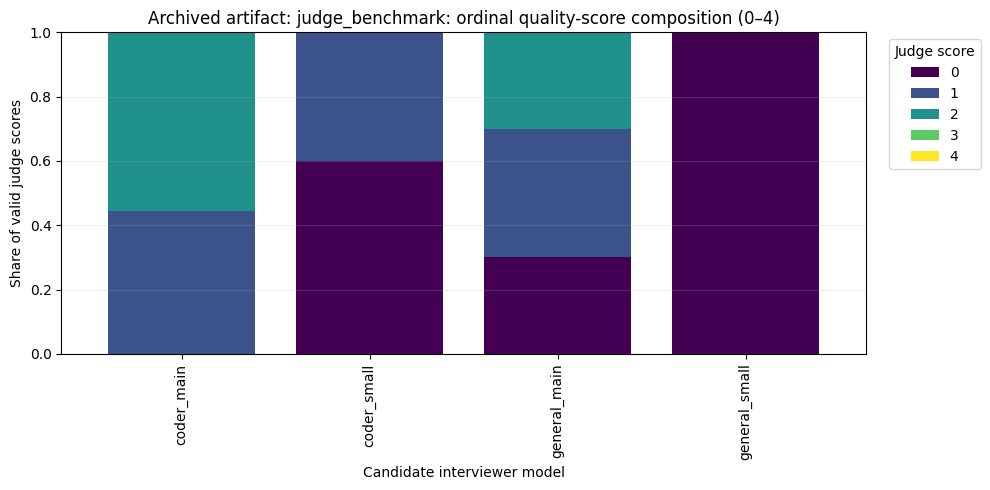

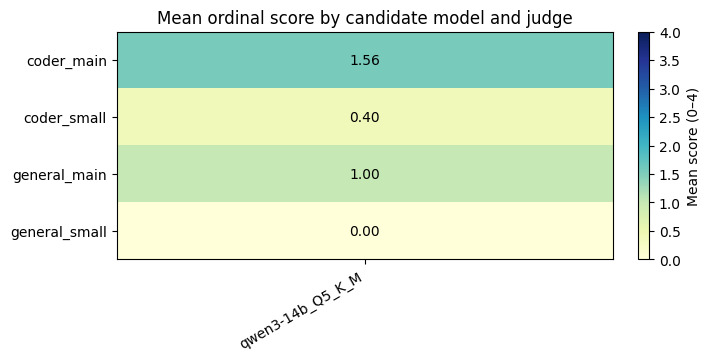

Pairwise rho heatmap omitted: no estimable judge pairs.
Panel MAD is unavailable when fewer than two judges scored an episode; null is not zero disagreement.
Archive limitation: run IDs do not match the selected experiment; judge panel size and archived profile also limit inference.


In [7]:
judge_dir = RUN_DIR / "judges"
current_csv = judge_dir / "judge_scores_long.csv"
current_partial = judge_dir / "judges_scores_partial.jsonl"
current_ids = set(results["run_id"].dropna().astype(str)) if "run_id" in results else set()
judge_records, archive_notes, archive_frames = {}, [], []
judge_bad = 0
eval_by_run = {str(r.get("run_id", "")): r for r in combined.values()}

def normalize_judge_csv(path):
    if not path.exists():
        return pd.DataFrame()
    try:
        return pd.read_csv(path, dtype=str, keep_default_na=False, low_memory=False)
    except (OSError, UnicodeDecodeError, pd.errors.ParserError) as exc:
        print("Judge CSV read issue:", path, exc)
        return pd.DataFrame()

# Prefer this run's partial and finalized files. A manual override is useful
# when judge output was saved elsewhere, but run IDs must still match.
partial, bad = read_jsonl(current_partial)
judge_bad += bad
for rec in partial:
    result = rec.get("result") or {}
    rid, jid = str(rec.get("run_id", "")), str(rec.get("judge_id", ""))
    if not rid or not jid:
        continue
    base = eval_by_run.get(rid, {})
    judge_records[(jid,rid)] = {"judge_id":jid,"run_id":rid,
        "candidate_model_id":base.get("model_id",""),"case_id":base.get("case_id",""),
        "case_group_id":base.get("case_group_id") or base.get("case_id",""),
        "score":result.get("score"),"parse_status":"success" if result.get("success") else result.get("failure_type","failed"),
        "latency_ms":result.get("latency_ms",np.nan)}

if JUDGE_RESULTS_OVERRIDE:
    override = Path(JUDGE_RESULTS_OVERRIDE)
    if not override.is_absolute(): override = ROOT / override
    candidate_paths = [override]
else:
    candidate_paths = [current_csv]
    candidate_paths += sorted(ROOT.glob("results_previous_runs_*/judge_benchmark/judge_scores_long.csv"))

for path in candidate_paths:
    frame = normalize_judge_csv(path)
    if frame.empty:
        continue
    ids = set(frame.get("run_id",pd.Series(dtype=str)).astype(str))
    matched_ids = ids & current_ids
    if path == current_csv or (JUDGE_RESULTS_OVERRIDE and path == override) or matched_ids:
        if not matched_ids:
            archive_notes.append({"File":str(path.relative_to(ROOT) if path.is_relative_to(ROOT) else path),
                                  "rows":len(frame),"matched current run IDs":0,"action":"not merged"})
        for rec in frame.to_dict("records"):
            rid, jid = str(rec.get("run_id","")), str(rec.get("judge_id",""))
            if rid and jid and rid in current_ids:
                judge_records[(jid,rid)] = rec
    else:
        archive_notes.append({"File":str(path.relative_to(ROOT) if path.is_relative_to(ROOT) else path),
                              "rows":len(frame),"matched current run IDs":0,"action":"archived; excluded"})
        archive_frames.append((path,frame))

judges = pd.DataFrame(judge_records.values())
if len(archive_notes):
    print("Judge artifacts that do not match the selected run:")
    display(pd.DataFrame(archive_notes))

def analyze_judge_rows(frame, title_prefix, current_run=False):
    if frame.empty:
        display(Markdown("**RQ3 status: INSUFFICIENT DATA.** There are no judge scores matched to the selected run ID set."))
        return None
    frame=frame.copy()
    frame["score"]=pd.to_numeric(frame.get("score"),errors="coerce")
    status=frame.get("parse_status",pd.Series("",index=frame.index)).astype(str).str.lower()
    valid=frame[status.isin(["success","ok",""]) & frame.score.between(0,4)].copy()
    failed=int((~status.isin(["success","ok",""])).sum())
    judge_count=frame["judge_id"].nunique() if "judge_id" in frame else 0
    print(f"{title_prefix}: {len(frame):,} judge/episode attempts; {len(valid):,} valid scores; {judge_count} distinct judge model(s); {failed:,} parse/judge failure(s) ({failed/max(len(frame),1):.1%}).")
    if len(valid)==0:
        print("No valid ordinal scores; quality and agreement are not estimable.")
        return {"valid":valid,"pairs":pd.DataFrame(),"panel":pd.DataFrame()}

    def rho(x,y):
        if len(x)<3:return np.nan
        rx=pd.Series(x,dtype=float).rank(method="average").to_numpy()
        ry=pd.Series(y,dtype=float).rank(method="average").to_numpy()
        if np.std(rx)==0 or np.std(ry)==0:return np.nan
        return float(np.corrcoef(rx,ry)[0,1])

    matrix=valid.pivot_table(index="run_id",columns="judge_id",values="score",aggfunc="mean")
    judge_ids=sorted(valid.judge_id.astype(str).unique())
    pairs=[]
    for i,a in enumerate(judge_ids):
        for b in judge_ids[i+1:]:
            common=matrix[[a,b]].dropna()
            value=rho(common[a].to_numpy(),common[b].to_numpy())
            pairs.append({"Judge A":a,"Judge B":b,"shared episodes":len(common),"Spearman rho":value,
                          "rho > 0.70":bool(pd.notna(value) and value>RHO_THRESHOLD)})
    pair_table=pd.DataFrame(pairs)
    if len(pair_table):
        display(pair_table.round(4))
        estimable=int(pair_table["Spearman rho"].notna().sum())
        passing=int(pair_table["rho > 0.70"].sum())
        if estimable >= 2:
            print(f"Reliability rule: {passing} judge pairs exceed rho > {RHO_THRESHOLD:.2f}; at least 2 are required.")
        else:
            print("Reliability rule: INSUFFICIENT — fewer than two judge-pair correlations are estimable.")
    elif judge_count < 2:
        print("Inter-rater reliability: INSUFFICIENT — one judge cannot establish agreement, rho, or panel MAD.")
    else:
        print("Inter-rater reliability: INSUFFICIENT — no pair has at least three shared episodes with varying ratings.")

    panel=[]
    for rid,part in valid.groupby("run_id"):
        scores=part.score.to_numpy(float); med=float(np.median(scores))
        panel.append({"run_id":rid,"panel_median":med,
                      "panel_MAD":float(np.median(np.abs(scores-med))) if len(scores)>=2 else np.nan,
                      "valid judges":len(scores)})
    panel=pd.DataFrame(panel).merge(valid[["run_id","candidate_model_id","case_group_id"]].drop_duplicates("run_id"),on="run_id",how="left")
    display(panel.groupby("candidate_model_id",dropna=False).agg(
        episodes=("run_id","nunique"),mean_panel_median=("panel_median","mean"),
        median_panel_median=("panel_median","median"),mean_panel_MAD=("panel_MAD","mean"),
        share_scores_3_or_4=("panel_median",lambda x:float((x>=3).mean()))).reset_index().round(3))

    # Ordinal score composition: stacked proportions preserve each of the 0–4 levels.
    score_counts=valid.groupby(["candidate_model_id","score"]).size().unstack(fill_value=0).reindex(columns=range(5),fill_value=0)
    proportions=score_counts.div(score_counts.sum(axis=1).replace(0,np.nan),axis=0)
    ax=proportions.plot(kind="bar",stacked=True,figsize=(10,5),colormap="viridis",width=.78)
    ax.set_ylim(0,1);ax.set_ylabel("Share of valid judge scores");ax.set_xlabel("Candidate interviewer model")
    ax.set_title(f"{title_prefix}: ordinal quality-score composition (0–4)")
    ax.legend(title="Judge score",bbox_to_anchor=(1.02,1),loc="upper left");ax.grid(axis="y",alpha=.2);plt.tight_layout();plt.show()

    # A model × judge heatmap is a matrix; pairwise rho heatmap is omitted if unestimable.
    means=valid.pivot_table(index="candidate_model_id",columns="judge_id",values="score",aggfunc="mean")
    fig,ax=plt.subplots(figsize=(max(7,1.2*means.shape[1]+3),max(3.5,.65*means.shape[0])),constrained_layout=True)
    image=ax.imshow(means.to_numpy(float),vmin=0,vmax=4,aspect="auto",cmap="YlGnBu")
    ax.set_xticks(range(len(means.columns)),means.columns,rotation=30,ha="right")
    ax.set_yticks(range(len(means.index)),means.index);ax.set_title("Mean ordinal score by candidate model and judge")
    for i in range(means.shape[0]):
        for j in range(means.shape[1]):
            if pd.notna(means.iloc[i,j]):ax.text(j,i,f"{means.iloc[i,j]:.2f}",ha="center",va="center")
    fig.colorbar(image,ax=ax,label="Mean score (0–4)");plt.show()

    if len(pair_table) and pair_table["Spearman rho"].notna().any():
        rho_matrix=pd.DataFrame(np.eye(len(judge_ids)),index=judge_ids,columns=judge_ids)
        for rec in pairs:
            rho_matrix.loc[rec["Judge A"],rec["Judge B"]]=rec["Spearman rho"]
            rho_matrix.loc[rec["Judge B"],rec["Judge A"]]=rec["Spearman rho"]
        fig,ax=plt.subplots(figsize=(max(5,.9*len(judge_ids)),max(4,.8*len(judge_ids))),constrained_layout=True)
        image=ax.imshow(rho_matrix.to_numpy(float),vmin=-1,vmax=1,cmap="coolwarm")
        ax.set_xticks(range(len(judge_ids)),judge_ids,rotation=35,ha="right");ax.set_yticks(range(len(judge_ids)),judge_ids)
        ax.set_title("Pairwise Spearman rho across shared episodes")
        for i in range(len(judge_ids)):
            for j in range(len(judge_ids)):
                value=rho_matrix.iloc[i,j]
                ax.text(j,i,"NA" if pd.isna(value) else f"{value:.2f}",ha="center",va="center")
        fig.colorbar(image,ax=ax,label="Spearman rho");plt.show()
    else:
        print("Pairwise rho heatmap omitted: no estimable judge pairs.")

    if len(panel) and panel["panel_MAD"].notna().any():
        maddata=[];labels=[]
        for model,part in panel.groupby("candidate_model_id",dropna=False):
            vals=part.panel_MAD.dropna().to_numpy(float)
            if len(vals):maddata.append(vals);labels.append(str(model))
        if maddata:
            fig,ax=plt.subplots(figsize=(max(7,len(labels)*1.2),4),constrained_layout=True)
            ax.boxplot(maddata,labels=labels,showfliers=True)
            ax.set_ylabel("Episode panel MAD (0 = unanimous)");ax.set_title("Judge-score disagreement by candidate model")
            ax.tick_params(axis="x",rotation=25);ax.grid(axis="y",alpha=.25);plt.show()
    else:
        print("Panel MAD is unavailable when fewer than two judges scored an episode; null is not zero disagreement.")
    return {"valid":valid,"pairs":pair_table,"panel":panel}

current_analysis = analyze_judge_rows(judges, "Selected full run", current_run=True) if len(judges) else None
if current_analysis is None:
    display(Markdown("**RQ3 status for the selected run: INSUFFICIENT DATA.** No judge scores match its run IDs."))
    if archive_frames:
        # Analyze an archive descriptively, but never present it as the selected full run.
        archive_path, archive_frame = archive_frames[0]
        print("Archived judge data are shown separately and are not used to answer the selected full run's RQ3.")
        archive_analysis=analyze_judge_rows(archive_frame, f"Archived artifact: {archive_path.parent.name}")
        print("Archive limitation: run IDs do not match the selected experiment; judge panel size and archived profile also limit inference.")
    else:
        print("No archived judge score file was found in the available workspace.")

## Overall evidence: support, contradiction, or insufficient data

Use the tables and plots above before reading the automatically generated summary below. A nonzero schema value or F1 match is only a minimal feasibility signal; compare the size and consistency of scores, model differences, source exposure, and evidence support. A confidence interval crossing zero means the available analysis did not resolve that model comparison, not that the models are equivalent.

The participant is synthetic and deterministic. Even strong scores establish technical feasibility on these benchmark cases only. They do not, on their own, prove that an LLM can elicit tacit knowledge from real employees. If judging is absent, RQ3 is still pending.


In [8]:
verdict_rows=[]
schema_values=pd.to_numeric(successful.get("schema_completeness",pd.Series(dtype=float)),errors="coerce")
f1_values=pd.to_numeric(successful.get("reference_fact_f1",pd.Series(dtype=float)),errors="coerce")
feasible_count=int(((schema_values>0)&(f1_values>0)).sum()) if len(successful) else 0
mean_schema=float(schema_values.mean()) if schema_values.notna().any() else np.nan
mean_f1=float(f1_values.mean()) if f1_values.notna().any() else np.nan
f1_nonzero=int((f1_values>0).sum()) if len(successful) else 0
stop_target=float(CONFIG.get("completion_threshold",0.75))
threshold_count=int((schema_values>=stop_target).sum()) if len(successful) else 0
verdict_rows.append({"Objective":"Technical feasibility on this benchmark",
 "Evidence criterion":"Nonzero schema progress and reference matches are only minimal feasibility signals; no formal minimum score/fraction is prespecified. Higher and more consistent scores are stronger evidence.",
 "Observed":f"Both >0: {feasible_count}/{len(successful)}; any F1 match: {f1_nonzero}/{len(successful)}; mean schema={mean_schema:.3f}; mean F1={mean_f1:.3f}; at/above configured 0.75 stop target={threshold_count}/{len(successful)}.",
 "Interpretation":"A limited technical feasibility signal on synthetic cases; magnitude and coverage matter, and it cannot establish real-employee tacit-knowledge extraction." if feasible_count else "No positive reference-matched feasibility signal in available successful episodes."})

if not episode_coverage_complete:
    rq1_status="INSUFFICIENT / PROVISIONAL: expected full run rows are missing."
elif len(resolved_schema):
    rq1_status=f"SUPPORTS measurable model differences for {len(resolved_schema)} pair(s) under the thesis CI rule."
else:
    rq1_status="NO DIFFERENCE RESOLVED: intervals include zero; this does not establish equivalence."
verdict_rows.append({"Objective":"RQ1: model differences","Evidence criterion":"Paired source-group bootstrap CI for schema-completeness difference excludes zero; F1 is supporting evidence.","Observed":rq1_status,"Interpretation":"Do not generalize beyond these source groups."})

if len(rq2_summary):
    rq2_status="DESCRIPTIVE ONLY: direction patterns are shown; thesis specifies no RQ2 pass threshold or formal test."
else:
    rq2_status="INSUFFICIENT: no successful episode metrics available."
verdict_rows.append({"Objective":"RQ2: elicitation efficiency","Evidence criterion":"Higher novelty/targeting; lower redundancy/turns while maintaining RQ1 quality. No fixed cutoffs.","Observed":rq2_status,"Interpretation":"Favorable directions are not a formal statistical confirmation."})

current_valid_judges = current_analysis["valid"] if current_analysis else pd.DataFrame()
if current_analysis is None or current_valid_judges.empty:
    rq3_status="INSUFFICIENT: no valid judge scores matched to selected full-run episode IDs."
elif current_valid_judges.judge_id.nunique()<3:
    rq3_status="INSUFFICIENT for the two-pair rule: fewer than three distinct judges."
elif len(current_analysis["pairs"]) and current_analysis["pairs"]["Spearman rho"].notna().sum()>=2:
    passed=int(current_analysis["pairs"]["rho > 0.70"].sum())
    rq3_status=f"{'MEETS' if passed>=2 else 'DOES NOT MEET'} the rule: {passed} judge pairs have rho > 0.70."
else:
    rq3_status="INSUFFICIENT: fewer than two pairwise correlations are estimable."
verdict_rows.append({"Objective":"RQ3: judge reliability / question quality","Evidence criterion":"At least two judge pairs with rho > 0.70; scores 3–4 are good/excellent descriptively.","Observed":rq3_status,"Interpretation":"A single judge or unmatched archived scores cannot answer RQ3."})
display(pd.DataFrame(verdict_rows))

print("Thesis claim boundary: no result in this synthetic benchmark can prove or disprove employee-level effectiveness. It can support or weaken only the stated proof-of-concept evidence on the available simulated cases.")

,Objective,Evidence criterion,Observed,Interpretation
0,Technical feasibility on this benchmark,Nonzero schema progress and reference matches ...,Both >0: 13/15; any F1 match: 13/15; mean sche...,A limited technical feasibility signal on synt...
1,RQ1: model differences,Paired source-group bootstrap CI for schema-co...,INSUFFICIENT / PROVISIONAL: expected full run ...,Do not generalize beyond these source groups.
2,RQ2: elicitation efficiency,Higher novelty/targeting; lower redundancy/tur...,DESCRIPTIVE ONLY: direction patterns are shown...,Favorable directions are not a formal statisti...
3,RQ3: judge reliability / question quality,At least two judge pairs with rho > 0.70; scor...,INSUFFICIENT: no valid judge scores matched to...,A single judge or unmatched archived scores ca...


Thesis claim boundary: no result in this synthetic benchmark can prove or disprove employee-level effectiveness. It can support or weaken only the stated proof-of-concept evidence on the available simulated cases.


## Reading the analysis responsibly

- RQ1: use paired forest plots for direction and uncertainty, then inspect distributions and source-group plots for concentration. The source document is the independent cluster.
- RQ2: assess novelty, targeting, redundancy, and turns together. Efficiency requires useful grounded information, not speed alone.
- RQ3: use only current-run scores matched by exact run ID. Report panel size, common trace count, parse failures, judge-pair rho, and MAD. Missing judge output means pending/insufficient evidence.
- Reference matching: the full source sentence inventory is compiled once; the episode metric denominator contains only sentence indices that the respondent disclosed. F1 remains a lexical proxy and can still undervalue semantic paraphrases.
- Scope: three documents support a bounded proof of concept, not a population-level conclusion about employees or organisations.

Plot choices follow the data structure: categorical box/violin and stacked bars for unordered models and ordinal judge scores, forest plots for paired effects with intervals, and heatmaps for score/coverage matrices. A line plot is used only for a genuinely ordered sequence such as turns or iterations. See the [Seaborn categorical plot guide](https://seaborn.pydata.org/tutorial/categorical.html), [Seaborn heatmap reference](https://seaborn.pydata.org/generated/seaborn.heatmap.html), and [Matplotlib plot-type guidance](https://matplotlib.org/stable/plot_types/index.html).
